<a href="https://colab.research.google.com/github/MashhuraSultonmuratova/nn-deep-learning-lab/blob/main/Lab1_Telecom_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 1 – Data Pre-processing on Telecom Customer Data (AfriTel)
**Course:** Lab: Neural Networks and Deep Learning – Chapter 1


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

REF_DATE = pd.Timestamp("2026-06-30")

# Raw files are never edited: we always work on copies
cust_raw  = pd.read_csv("customers.csv")
usage_raw = pd.read_csv("monthly_usage.csv")

## Part 0 – First exploration (EDA)

In [2]:
# 0.1 Rows and columns
print("customers.csv     :", cust_raw.shape[0], "rows,", cust_raw.shape[1], "columns")
print("monthly_usage.csv :", usage_raw.shape[0], "rows,", usage_raw.shape[1], "columns")

customers.csv     : 1225 rows, 9 columns
monthly_usage.csv : 6689 rows, 9 columns


In [3]:
# 0.2 Type and number of missing values per column
for name, df in [("customers", cust_raw), ("monthly_usage", usage_raw)]:
    print("---", name)
    print(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum()}).to_string())

--- customers
                      dtype  missing
customer_id          object        0
gender               object       24
date_of_birth        object       43
city                 object       25
contract_type        object        0
tenure_months       float64       48
monthly_charge_usd  float64       36
num_complaints        int64        0
churn                object        0
--- monthly_usage
                   dtype  missing
cust_no            int64        0
month             object        0
minutes_day      float64      134
minutes_evening  float64        0
minutes_night    float64        0
total_minutes    float64        0
sms_count          int64        0
data_volume      float64        0
data_unit         object        0


In [4]:
# 0.3 Distinct values of the text columns (repr() makes hidden spaces visible)
for col in ["gender", "city", "contract_type", "churn"]:
    vals = sorted(cust_raw[col].dropna().unique())
    print(f"{col}: {len(vals)} distinct values ->", [repr(v) for v in vals], "\n")
print("data_unit:", usage_raw.data_unit.unique())
print("month    :", sorted(usage_raw.month.unique()))

gender: 10 distinct values -> ["' M'", "'F'", "'F '", "'Female'", "'M'", "'Male'", "'f'", "'female'", "'m'", "'male'"] 

city: 22 distinct values -> ["'ADDIS ABABA'", "'Addis Ababa'", "'Addis-Ababa'", "'Awassa'", "'Bahir Dar'", "'Bahirdar'", "'Goma'", "'Gondar'", "'Gonder'", "'Hawassa'", "'KINSHASA'", "'Kinshasa'", "'Kinshasa '", "'Kisangani'", "'Lubumbachi'", "'Lubumbashi'", "'addis ababa'", "'bahir dar'", "'goma'", "'kinshasa'", "'kisangani'", "'lubumbashi'"] 

contract_type: 8 distinct values -> ["'POSTPAID'", "'PREPAID'", "'Post-paid'", "'Postpaid'", "'Pre-paid'", "'Prepaid'", "'postpaid'", "'prepaid'"] 

churn: 2 distinct values -> ["'No'", "'Yes'"] 

data_unit: ['MB' 'GB']
month    : ['2026-01', '2026-02', '2026-03', '2026-04', '2026-05', '2026-06']


In [5]:
# 0.4 Summary statistics of the numeric columns
print(cust_raw.describe().T.round(2).to_string(), "\n")
print(usage_raw.describe().T.round(2).to_string(), "\n")
dob = pd.to_datetime(cust_raw.date_of_birth)
print("date_of_birth: min =", dob.min().date(), "| max =", dob.max().date())

                     count   mean     std    min    25%    50%    75%     max
tenure_months       1177.0  40.06   24.04 -12.00  19.00  39.00  61.00    96.0
monthly_charge_usd  1189.0  74.62  707.15   8.43  16.67  21.89  31.41  9999.0
num_complaints      1225.0   0.89    0.97   0.00   0.00   1.00   1.00     5.0 

                  count      mean        std   min     25%      50%      75%        max
cust_no          6689.0    604.09     348.97   1.0  300.00   603.00   905.00     1383.0
minutes_day      6555.0    220.93     138.02  13.1  127.60   186.70   276.85     1860.3
minutes_evening  6689.0    143.85      91.88   0.0   81.90   122.30   181.40     1241.4
minutes_night    6689.0     44.27      29.01   0.0   25.10    38.10    56.70      376.9
total_minutes    6689.0    409.17     258.68  13.1  235.40   345.80   512.40     3473.7
sms_count        6689.0     51.21      35.17   5.0   28.00    42.00    64.00      315.0
data_volume      6689.0  21934.32  440357.38  -1.0    4.47  1566.97  3

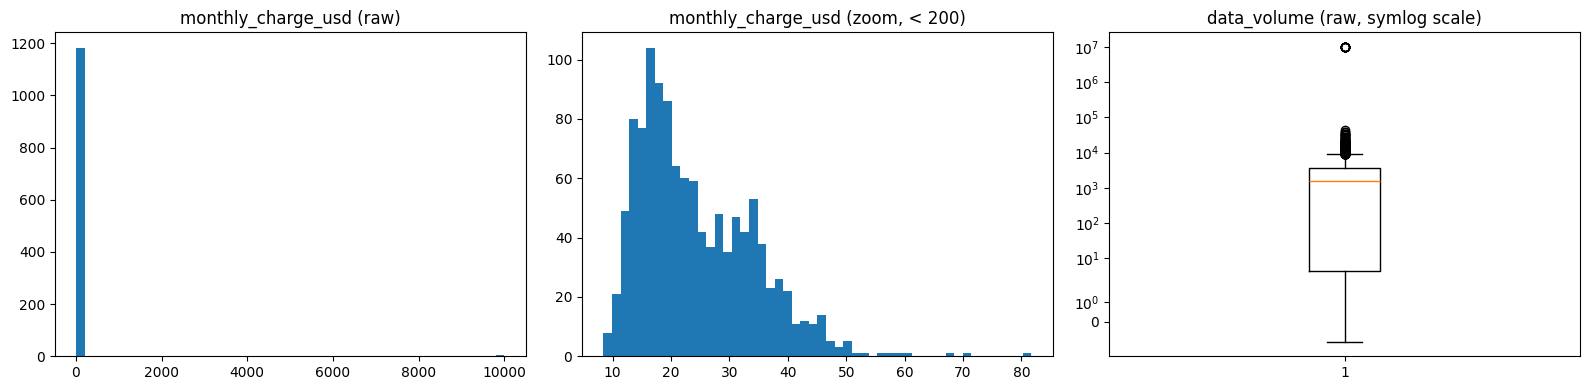

In [6]:
# 0.5 Histogram of monthly_charge_usd and box plot of data_volume (raw data)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(cust_raw.monthly_charge_usd.dropna(), bins=50)
ax[0].set_title("monthly_charge_usd (raw)")
ax[1].hist(cust_raw.monthly_charge_usd[cust_raw.monthly_charge_usd < 200].dropna(), bins=50)
ax[1].set_title("monthly_charge_usd (zoom, < 200)")
ax[2].boxplot(usage_raw.data_volume)
ax[2].set_yscale("symlog")
ax[2].set_title("data_volume (raw, symlog scale)")
plt.tight_layout(); plt.show()

### 0.6 Problems found (to fix in the next parts)
1. **Duplicates**: exact duplicate rows in both files.
2. **Inconsistent categories**: gender (`M`, ` M`, `male`, `Female`, `f` …), city (case, spaces, hyphens, typos such as *Gonder*, *Awassa*, *Lubumbachi*), contract_type (`PREPAID`, `Pre-paid` …).
3. **Impossible values**: negative `tenure_months`, `monthly_charge_usd = 9999` (placeholder), birth dates giving an age < 16 or > 100, `data_volume` = -1 or 9 999 999.
4. **Missing values** in gender, date_of_birth, city, tenure_months, monthly_charge_usd and minutes_day.
5. **Different units**: `data_volume` is in MB *or* GB depending on `data_unit`.
6. **Different ID formats**: `CUST-00052` (CRM) vs `52` (network system).
7. **Different granularity**: one row per customer vs one row per customer per month.
8. **Different scales** of the numeric columns, and a redundant column (`total_minutes`).
9. **Heavy right tail** in usage and data volume (possible outliers).

## Part 1 – Data cleaning

### 1.1 Duplicates

In [7]:
cust  = cust_raw.copy()
usage = usage_raw.copy()

n_dup_c, n_dup_u = cust.duplicated().sum(), usage.duplicated().sum()
cust  = cust.drop_duplicates().reset_index(drop=True)
usage = usage.drop_duplicates().reset_index(drop=True)
print("Exact duplicates removed: customers =", n_dup_c, "| usage =", n_dup_u)
print("Rows now: customers =", len(cust), "| usage =", len(usage))

# Are the keys unique now?
print("customer_id unique         :", cust.customer_id.is_unique)
print("(cust_no, month) unique    :", not usage.duplicated(["cust_no", "month"]).any())

Exact duplicates removed: customers = 25 | usage = 30
Rows now: customers = 1200 | usage = 6659
customer_id unique         : True
(cust_no, month) unique    : True


### 1.2 Inconsistent data

In [8]:
# gender -> only M or F  (strip spaces, lower case, keep the first letter)
cust["gender"] = cust["gender"].str.strip().str.lower().str[0].str.upper()

# city -> one spelling per city. Build a "key" without spaces/hyphens, then map to the correct name
city_map = {
    "kinshasa": "Kinshasa", "lubumbashi": "Lubumbashi", "lubumbachi": "Lubumbashi",
    "goma": "Goma", "kisangani": "Kisangani",
    "addisababa": "Addis Ababa", "gondar": "Gondar", "gonder": "Gondar",
    "bahirdar": "Bahir Dar", "hawassa": "Hawassa", "awassa": "Hawassa",
}
key = cust["city"].str.lower().str.replace(r"[\s\-]", "", regex=True)
cust["city"] = key.map(city_map)
assert cust.city.notna().sum() == key.notna().sum(), "some city spelling is not mapped!"

# contract_type -> Prepaid / Postpaid
key = cust["contract_type"].str.lower().str.replace(r"[\s\-]", "", regex=True)
cust["contract_type"] = key.map({"prepaid": "Prepaid", "postpaid": "Postpaid"})
assert cust.contract_type.notna().all()

print(cust.gender.value_counts(dropna=False).to_dict())
print(cust.city.value_counts(dropna=False).to_dict())
print("Number of cities:", cust.city.nunique())
print(cust.contract_type.value_counts().to_dict())

{'M': 636, 'F': 540, nan: 24}
{'Kinshasa': 355, 'Addis Ababa': 299, 'Lubumbashi': 140, 'Gondar': 87, 'Bahir Dar': 83, 'Goma': 82, 'Hawassa': 69, 'Kisangani': 61, nan: 24}
Number of cities: 8
{'Prepaid': 863, 'Postpaid': 337}


### 1.3 Invalid values -> NaN

In [9]:
def age_on(dob, ref=REF_DATE):
    """Exact age in completed years at the reference date (works on a datetime Series)."""
    had_birthday = (dob.dt.month < ref.month) | ((dob.dt.month == ref.month) & (dob.dt.day <= ref.day))
    return ref.year - dob.dt.year - (~had_birthday).astype(int)

cust["date_of_birth"] = pd.to_datetime(cust["date_of_birth"])
age_tmp = age_on(cust["date_of_birth"])

masks = {
    "tenure_months < 0":               (cust.tenure_months < 0, "cust", "tenure_months"),
    "monthly_charge_usd == 9999":      (cust.monthly_charge_usd == 9999, "cust", "monthly_charge_usd"),
    "age < 16 or age > 100":           ((age_tmp < 16) | (age_tmp > 100), "cust", "date_of_birth"),
    "data_volume < 0 or > 1,000,000":  ((usage.data_volume < 0) | (usage.data_volume > 1_000_000), "usage", "data_volume"),
}
invalid_counts = {}
for rule, (mask, table, col) in masks.items():
    invalid_counts[rule] = int(mask.sum())
    (cust if table == "cust" else usage).loc[mask, col] = np.nan
    print(f"{rule:35s} -> {mask.sum()} values replaced by NaN")
print("   (age < 16:", int((age_tmp < 16).sum()), "| age > 100:", int((age_tmp > 100).sum()), "| negative volume:", int((usage.data_volume < 0).sum()), "| volume > 1,000,000:", int((usage.data_volume > 1_000_000).sum()), ")")

tenure_months < 0                   -> 8 values replaced by NaN
monthly_charge_usd == 9999          -> 6 values replaced by NaN
age < 16 or age > 100               -> 5 values replaced by NaN
data_volume < 0 or > 1,000,000      -> 32 values replaced by NaN
   (age < 16: 3 | age > 100: 2 | negative volume: 0 | volume > 1,000,000: 0 )


### 1.4 Missing values

In [10]:
# Share of customers with at least one missing value (before filling) -> used in the justification
cols_c = ["gender", "date_of_birth", "city", "tenure_months", "monthly_charge_usd"]
print("Missing values per column (after step 1.3):")
print(cust[cols_c].isna().sum().to_string())
share_rows_missing = cust[cols_c].isna().any(axis=1).mean()
print(f"\nCustomers with at least one missing value: {cust[cols_c].isna().any(axis=1).sum()} ({share_rows_missing:.1%})")
has_na = cust[cols_c].isna().any(axis=1)
print("Churn rate: rows with a missing value =", round((cust.churn[has_na] == "Yes").mean(), 3), "| complete rows =", round((cust.churn[~has_na] == "Yes").mean(), 3))

# Skewness decides between mean and median  (|skew| > 0.5 -> clearly skewed -> median)
fill_info = {}
for col in ["tenure_months", "monthly_charge_usd"]:
    sk = cust[col].skew()
    use_median = abs(sk) > 0.5
    value = cust[col].median() if use_median else cust[col].mean()
    fill_info[col] = (sk, "median" if use_median else "mean", value)
    print(f"{col:20s} skewness = {sk:6.2f} | mean = {cust[col].mean():7.2f} | median = {cust[col].median():7.2f} -> fill with the {'median' if use_median else 'mean'}")
    cust[col] = cust[col].fillna(value)

# Categorical columns -> mode
for col in ["gender", "city"]:
    cust[col] = cust[col].fillna(cust[col].mode()[0])

# date_of_birth -> median date
dob_median = cust["date_of_birth"].median()
cust["date_of_birth"] = cust["date_of_birth"].fillna(dob_median)
print("\nMedian date of birth used:", dob_median.date())
print("Remaining NaN in customers:", int(cust.isna().sum().sum()))

Missing values per column (after step 1.3):
gender                24
date_of_birth         47
city                  24
tenure_months         56
monthly_charge_usd    42

Customers with at least one missing value: 180 (15.0%)
Churn rate: rows with a missing value = 0.133 | complete rows = 0.141
tenure_months        skewness =   0.17 | mean =   40.26 | median =   39.00 -> fill with the mean
monthly_charge_usd   skewness =   0.97 | mean =   24.33 | median =   21.84 -> fill with the median

Median date of birth used: 1989-03-13
Remaining NaN in customers: 0


In [11]:
# minutes_day: exact reconstruction  total = day + evening + night  ->  day = total - evening - night
known = usage.minutes_day.notna()
max_err = (usage.total_minutes - usage.minutes_day - usage.minutes_evening - usage.minutes_night)[known].abs().max()
print("Check on complete rows: max |total - (day+evening+night)| =", round(max_err, 3))

missing_day = usage.minutes_day.isna()
rebuilt = (usage.total_minutes - usage.minutes_evening - usage.minutes_night).round(1)
n_rebuildable = int((missing_day & (rebuilt >= 0)).sum())
usage.loc[missing_day, "minutes_day"] = rebuilt[missing_day]
print("Missing minutes_day:", int(missing_day.sum()), "| rebuilt exactly:", n_rebuildable)
print("Remaining NaN in minutes_day:", int(usage.minutes_day.isna().sum()))

Check on complete rows: max |total - (day+evening+night)| = 0.0
Missing minutes_day: 133 | rebuilt exactly: 133
Remaining NaN in minutes_day: 0


**Why not delete every row with a missing value?** About 15 % of the customers (180 of 1 200) have at least one missing value in the CRM file, and the missing values are spread over five different columns, so most of these customers have only *one* problem and are otherwise complete. Deleting them would waste a small dataset and could bias the churn target (see the churn rates above). In the usage file, the 133 missing `minutes_day` values are exactly recoverable from `total_minutes`, so deleting those rows would destroy information we can rebuild for free.

### 1.5 Noisy data – smoothing by binning (10 equal-frequency bins)

In [12]:
cust["charge_bin"] = pd.qcut(cust["monthly_charge_usd"], q=10, duplicates="drop")
cust["charge_smoothed"] = cust.groupby("charge_bin", observed=True)["monthly_charge_usd"].transform("mean")

bin_means = cust.groupby("charge_bin", observed=True)["monthly_charge_usd"].agg(["count", "min", "max", "mean"]).round(2)
print("Number of bins:", len(bin_means))
print(bin_means.to_string())

Number of bins: 10
                  count    min    max   mean
charge_bin                                  
(8.429, 13.779]     120   8.43  13.77  12.10
(13.779, 15.954]    120  13.78  15.93  14.91
(15.954, 17.747]    120  15.96  17.74  16.83
(17.747, 19.816]    120  17.75  19.81  18.73
(19.816, 21.845]    141  19.82  21.84  21.09
(21.845, 24.438]     99  21.85  24.43  23.11
(24.438, 28.71]     121  24.45  28.71  26.58
(28.71, 32.792]     119  28.75  32.77  30.89
(32.792, 37.347]    120  32.88  37.34  34.92
(37.347, 81.7]      120  37.41  81.70  43.65


### 1.6 Outliers in the data volume

Q1 = 1565 MB | Q3 = 4674 MB | IQR = 3109 MB | fence = 9339 MB
Points above the fence: 407 (6.1% of the rows), 131 different customers
Largest value: 53537 MB
       minutes_day  sms_count  total_minutes  data_mb
heavy                                                
False        186.8       41.0          345.9   2568.8
True         183.1       54.0          341.0  12583.2


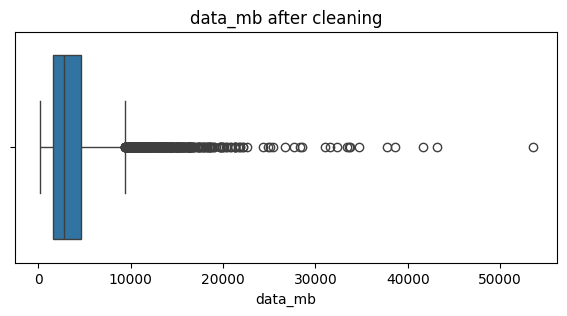

In [13]:
# Convert everything to MB (1 GB = 1024 MB)
usage["data_mb"] = np.where(usage.data_unit == "GB", usage.data_volume * 1024, usage.data_volume)

vol = usage["data_mb"].dropna()
q1, q3 = vol.quantile([0.25, 0.75])
iqr = q3 - q1
fence = q3 + 1.5 * iqr
is_out = usage["data_mb"] > fence
print(f"Q1 = {q1:.0f} MB | Q3 = {q3:.0f} MB | IQR = {iqr:.0f} MB | fence = {fence:.0f} MB")
print("Points above the fence:", int(is_out.sum()), f"({is_out.mean():.1%} of the rows),", usage.loc[is_out, "cust_no"].nunique(), "different customers")
print("Largest value:", round(vol.max()), "MB")

# Are they errors? Compare their behaviour with the other rows
print(usage.assign(heavy=is_out).groupby("heavy")[["minutes_day", "sms_count", "total_minutes", "data_mb"]].median().round(1).to_string())

plt.figure(figsize=(7, 3)); sns.boxplot(x=vol); plt.title("data_mb after cleaning"); plt.show()

**Decision:** the points above the fence are **real heavy users, not errors**. After removing the placeholders (-1 and 9 999 999), the largest value is about 53 000 MB (≈ 52 GB per month): a high but physically possible volume, nothing like the 9 999 999 placeholder. The 407 rows come from 131 different customers (about 3 months each), i.e. a *persistent* behaviour of some customers, and not isolated glitches. I therefore **keep** them (deleting them would remove exactly the heavy-usage customers that matter for the business), and I would reduce their influence with a log-transform or a robust scaler if a model turns out to be sensitive to them. Only the impossible values are treated as errors.

## Part 2 – Data integration

In [14]:
# 2.1 Common key
cust["cust_no"] = cust["customer_id"].str.replace("CUST-", "", regex=False).astype(int)

# 2.2 Aggregation: one row per customer
usage_agg = usage.groupby("cust_no").agg(
    months_recorded     =("month", "nunique"),
    minutes_day_avg     =("minutes_day", "mean"),
    minutes_evening_avg =("minutes_evening", "mean"),
    minutes_night_avg   =("minutes_night", "mean"),
    total_minutes_avg   =("total_minutes", "mean"),
    sms_avg             =("sms_count", "mean"),
    data_mb_avg         =("data_mb", "mean"),
).reset_index()
print("Aggregated usage:", usage_agg.shape)

# 2.4b  usage customers unknown to the CRM
orphans = sorted(set(usage_agg.cust_no) - set(cust.cust_no))
print("cust_no in usage but not in CRM:", len(orphans), "->", orphans[:15])

# 2.3 Left join (CRM is the reference)
df = cust.merge(usage_agg, on="cust_no", how="left")
print("Merged shape:", df.shape)

Aggregated usage: (1175, 8)
cust_no in usage but not in CRM: 15 -> [1209, 1212, 1216, 1217, 1233, 1246, 1248, 1250, 1269, 1282, 1286, 1294, 1317, 1360, 1383]
Merged shape: (1200, 19)


In [15]:
# 2.4a  Customers without usage records
usage_cols = ["minutes_day_avg", "minutes_evening_avg", "minutes_night_avg", "total_minutes_avg", "sms_avg", "data_mb_avg"]
df["has_usage"] = df["months_recorded"].notna().astype(int)
n_no_usage = int((df.has_usage == 0).sum())
print("Customers without any usage record:", n_no_usage)
print("Churn rate of these customers:", round((df.loc[df.has_usage == 0, "churn"] == "Yes").mean(), 3),
      "| of the others:", round((df.loc[df.has_usage == 1, "churn"] == "Yes").mean(), 3))

# no usage = no activity -> 0 (the flag has_usage keeps the information that this is not a measured zero)
df[usage_cols + ["months_recorded"]] = df.loc[:, usage_cols + ["months_recorded"]].where(df.has_usage == 1, 0)

# customers WITH usage rows whose data volume was invalid in every month -> median of the other customers
all_bad = (df.has_usage == 1) & df.data_mb_avg.isna()
print("Customers whose data volume is missing in all their months:", int(all_bad.sum()))
df["data_mb_avg"] = df["data_mb_avg"].fillna(df.loc[df.has_usage == 1, "data_mb_avg"].median())
df["months_recorded"] = df["months_recorded"].astype(int)

# 2.5  One row per customer?
print("Rows:", len(df), "| unique customer_id:", df.customer_id.nunique(), "| one row per customer:", df.customer_id.is_unique)
print("Remaining NaN:", int(df[[c for c in df.columns if c != "charge_bin"]].isna().sum().sum()))

Customers without any usage record: 40
Churn rate of these customers: 0.15 | of the others: 0.14
Customers whose data volume is missing in all their months: 0
Rows: 1200 | unique customer_id: 1200 | one row per customer: True
Remaining NaN: 0


- **Customers without usage:** their usage columns are set to **0** (no recorded traffic = no activity) and `months_recorded = 0`. The extra column `has_usage` lets a model distinguish them from customers who really measured 0. Using the mean would invent a behaviour that was never observed.
- **cust_no only in the usage file:** these records have no CRM row, so we have no churn label and no profile for them: they are **dropped** by the left join (they cannot be used for supervised learning).

## Part 3 – Data transformation

In [16]:
# 3.1 Attribute construction
df["age"] = age_on(df["date_of_birth"]).astype(int)
df["is_senior"] = (df["age"] >= 60).astype(int)
print("Age: min =", df.age.min(), "| max =", df.age.max(), "| mean =", round(df.age.mean(), 1))
print("Senior customers (age >= 60):", int(df.is_senior.sum()))

Age: min = 18 | max = 85 | mean = 37.4
Senior customers (age >= 60): 64


In [17]:
# 3.2 Generalization: city -> country
country_of = {"Kinshasa": "DR Congo", "Lubumbashi": "DR Congo", "Goma": "DR Congo", "Kisangani": "DR Congo",
              "Addis Ababa": "Ethiopia", "Gondar": "Ethiopia", "Bahir Dar": "Ethiopia", "Hawassa": "Ethiopia"}
df["country"] = df["city"].map(country_of)
df["churn_bin"] = (df["churn"] == "Yes").astype(int)
print(df.groupby("country")["churn_bin"].agg(customers="count", churners="sum", churn_rate="mean").round(3).to_string())
print("Overall churn rate:", round(df.churn_bin.mean(), 3))

          customers  churners  churn_rate
country                                  
DR Congo        662        86       0.130
Ethiopia        538        82       0.152
Overall churn rate: 0.14


In [18]:
# 3.3 Normalization
num_cols = ["tenure_months", "monthly_charge_usd", "num_complaints", "age"] + usage_cols

mm = (df[num_cols] - df[num_cols].min()) / (df[num_cols].max() - df[num_cols].min())          # min-max [0, 1]
zs = (df[num_cols] - df[num_cols].mean()) / df[num_cols].std(ddof=0)                           # z-score
mm.columns = [c + "_mm" for c in num_cols]
zs.columns = [c + "_z" for c in num_cols]
df = pd.concat([df, mm, zs], axis=1)

print("Min-max  -> min / max :")
print(pd.DataFrame({"min": mm.min(), "max": mm.max()}).round(3).to_string())
print("\nZ-score -> mean / std :")
print(pd.DataFrame({"mean": zs.mean(), "std": zs.std(ddof=0)}).round(3).to_string())

Min-max  -> min / max :
                        min  max
tenure_months_mm        0.0  1.0
monthly_charge_usd_mm   0.0  1.0
num_complaints_mm       0.0  1.0
age_mm                  0.0  1.0
minutes_day_avg_mm      0.0  1.0
minutes_evening_avg_mm  0.0  1.0
minutes_night_avg_mm    0.0  1.0
total_minutes_avg_mm    0.0  1.0
sms_avg_mm              0.0  1.0
data_mb_avg_mm          0.0  1.0

Z-score -> mean / std :
                       mean  std
tenure_months_z         0.0  1.0
monthly_charge_usd_z    0.0  1.0
num_complaints_z       -0.0  1.0
age_z                  -0.0  1.0
minutes_day_avg_z      -0.0  1.0
minutes_evening_avg_z  -0.0  1.0
minutes_night_avg_z     0.0  1.0
total_minutes_avg_z    -0.0  1.0
sms_avg_z               0.0  1.0
data_mb_avg_z           0.0  1.0


**Why k-NN needs normalization:** k-NN predicts from the *distance* between customers. A column in large units (e.g. `data_mb_avg` in thousands of MB) dominates the Euclidean distance and a column in small units (e.g. `num_complaints`, 0–5) is almost ignored, so the neighbours are chosen almost only from the large-scale column. After scaling, every feature contributes comparably to the distance.

In [19]:
# 3.4 Discretization
df["age_group"] = pd.cut(df["age"], bins=[0, 18, 44, 60, np.inf], labels=["<18", "18-44", "44-60", "60+"], right=False)
df["tenure_group"] = pd.cut(df["tenure_months"], bins=[-np.inf, 12, 24, 48, np.inf], labels=["0-12", "13-24", "25-48", ">48"])

print(df.age_group.value_counts().sort_index().to_string(), "\n")
print(df.groupby("tenure_group", observed=True)["churn_bin"].agg(customers="count", churn_rate="mean").round(3).to_string())

age_group
<18        0
18-44    854
44-60    282
60+       64 

              customers  churn_rate
tenure_group                       
0-12                179       0.324
13-24               177       0.198
25-48               395       0.132
>48                 449       0.051


**Conclusion:** the churn rate is much higher in the first year (0–12 months) than in the longer-tenure groups and falls as the tenure grows. New customers are the most at risk: AfriTel should focus its retention actions (welcome offers, follow-up calls) on them.

In [20]:
# 3.5 (Bonus) Encoding
enc = pd.get_dummies(df[["gender", "contract_type", "country"]], drop_first=True, dtype=int)
enc = enc.rename(columns={"contract_type_Prepaid": "contract_prepaid"})
df = pd.concat([df, enc], axis=1)
print(enc.head(3).to_string())
print("churn 0/1:", df.churn_bin.value_counts().to_dict())

   gender_M  contract_prepaid  country_Ethiopia
0         1                 0                 0
1         0                 1                 0
2         1                 0                 1
churn 0/1: {0: 1032, 1: 168}


## Part 4 – Data reduction

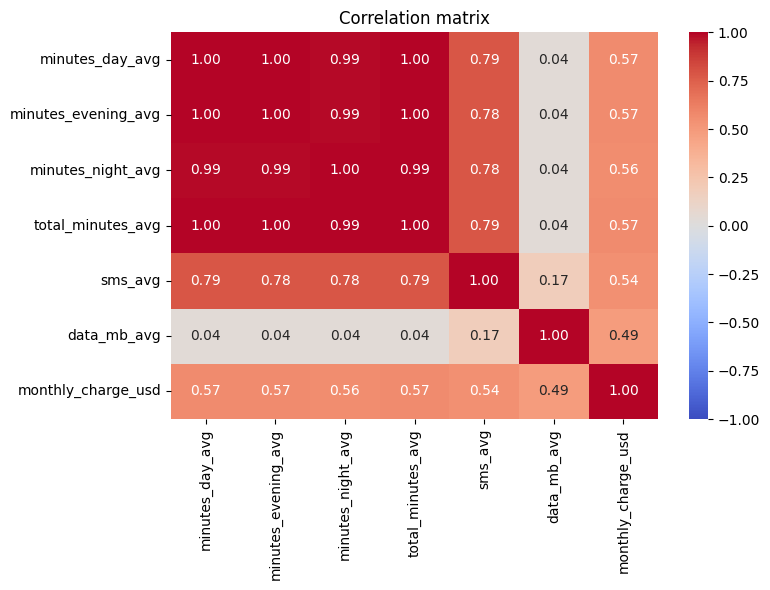

Pairs with |r| > 0.9: [('minutes_day_avg', 'minutes_evening_avg', np.float64(0.997)), ('minutes_day_avg', 'minutes_night_avg', np.float64(0.991)), ('minutes_day_avg', 'total_minutes_avg', np.float64(1.0)), ('minutes_evening_avg', 'minutes_night_avg', np.float64(0.989)), ('minutes_evening_avg', 'total_minutes_avg', np.float64(0.999)), ('minutes_night_avg', 'total_minutes_avg', np.float64(0.993))]
total_minutes_avg == day + evening + night : True

Correlation of monthly_charge_usd with the others:
minutes_day_avg        0.57
minutes_evening_avg    0.57
minutes_night_avg      0.56
total_minutes_avg      0.57
sms_avg                0.54
data_mb_avg            0.49
monthly_charge_usd     1.00
Correlation of sms_avg / data_mb_avg with the minutes:
             minutes_day_avg  minutes_evening_avg  minutes_night_avg
sms_avg                 0.79                 0.78               0.78
data_mb_avg             0.04                 0.04               0.04


In [21]:
# 4.1 Redundant features
corr_cols = usage_cols + ["monthly_charge_usd"]
corr = df[corr_cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix"); plt.tight_layout(); plt.show()

pairs = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(corr_cols) for b in corr_cols[i + 1:] if abs(corr.loc[a, b]) > 0.9]
print("Pairs with |r| > 0.9:", pairs)

exact = np.allclose(df.total_minutes_avg, df[["minutes_day_avg", "minutes_evening_avg", "minutes_night_avg"]].sum(axis=1), atol=0.15)
print("total_minutes_avg == day + evening + night :", exact)
print("\nCorrelation of monthly_charge_usd with the others:")
print(corr["monthly_charge_usd"].round(2).to_string())
print("Correlation of sms_avg / data_mb_avg with the minutes:")
print(corr.loc[["sms_avg", "data_mb_avg"], ["minutes_day_avg", "minutes_evening_avg", "minutes_night_avg"]].round(2).to_string())

In [22]:
# 4.2 PCA on the 6 standardized usage averages
X = StandardScaler().fit_transform(df[usage_cols])
pca = PCA().fit(X)
var = pca.explained_variance_ratio_
res = pd.DataFrame({"explained": var, "cumulative": var.cumsum()}, index=[f"PC{i+1}" for i in range(len(var))])
print(res.round(4).to_string())
n90 = int(np.argmax(res.cumulative.values >= 0.90) + 1)
n95 = int(np.argmax(res.cumulative.values >= 0.95) + 1)
print(f"\nComponents for 90 % of the variance: {n90} | for 95 %: {n95}")

     explained  cumulative
PC1     0.7773      0.7773
PC2     0.1700      0.9473
PC3     0.0501      0.9974
PC4     0.0022      0.9996
PC5     0.0004      1.0000
PC6     0.0000      1.0000

Components for 90 % of the variance: 2 | for 95 %: 3


In [23]:
# Final table: remove the redundant column, keep a clean, numeric, model-ready table
df_red = df.drop(columns=["total_minutes_avg", "total_minutes_avg_mm", "total_minutes_avg_z"])

mm_cols = [c for c in df_red.columns if c.endswith("_mm")]
final = df_red[
    ["customer_id", "churn_bin", "tenure_months", "monthly_charge_usd", "charge_smoothed", "num_complaints", "age", "is_senior",
     "months_recorded", "has_usage", "minutes_day_avg", "minutes_evening_avg", "minutes_night_avg", "sms_avg", "data_mb_avg",
     "gender_M", "contract_prepaid", "country_Ethiopia"] + mm_cols
].rename(columns={"churn_bin": "churn"}).copy()
final["age_group_code"]    = df_red["age_group"].cat.codes
final["tenure_group_code"] = df_red["tenure_group"].cat.codes

assert final.isna().sum().sum() == 0 and final.customer_id.is_unique
final.to_csv("customers_clean.csv", index=False)
print("Final table:", final.shape, "-> saved as customers_clean.csv")

Final table: (1200, 29) -> saved as customers_clean.csv


In [24]:
# 4.3 Size
size_raw   = cust_raw.memory_usage(deep=True).sum() + usage_raw.memory_usage(deep=True).sum()
size_final = final.memory_usage(deep=True).sum()
print(f"Raw files   : customers {cust_raw.memory_usage(deep=True).sum()/1024:.0f} KB + usage {usage_raw.memory_usage(deep=True).sum()/1024:.0f} KB = {size_raw/1024:.0f} KB  ({len(cust_raw) + len(usage_raw)} rows)")
print(f"Final table : {size_final/1024:.0f} KB  ({len(final)} rows, {final.shape[1]} columns)")
print(f"Reduction   : {1 - size_final/size_raw:.1%}  (factor {size_raw/size_final:.1f})")

Raw files   : customers 425 KB + usage 1065 KB = 1490 KB  (7914 rows)
Final table : 315 KB  (1200 rows, 29 columns)
Reduction   : 78.8%  (factor 4.7)


**4.4 Think ahead.** The mean, median, min/max (and standard deviation) must be computed on the **training set only**, then applied unchanged to the test set. The test set plays the role of *future, unseen customers*: if its values were used to compute the fill values or the scaling parameters, information from the test set would leak into the training (**data leakage**), and the test score would be too optimistic and would not reflect the real performance of the model.